<a href="https://colab.research.google.com/github/GrimiDev12/Programaci-n-para-IA-gpo-001/blob/main/PIAPPIAAD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Producto Integrador de Aprendizaje
## Arbol de Decision para cancer de mama
Ángel Eliseo Cristán Palacios - 2207776

Edgar Aldair Grimaldo Avila - 2163608

Braulio Emmanuel González López - 2276375

Santiago Alonso Moreno López - 2189244

Gael Cárdenas Bernal - 2208816

## Ejercicio 1: Carga del Conjunto de Datos Público

Descripcion: Se importan las librerías de ciencia de datos y aprendizaje automático (pandas, numpy, matplotlib y scikit-learn). Posteriormente, se carga directamente el dataset público Breast Cancer Wisconsin (Diagnostic)desde el repositorio de UCI Machine Learning mediante pd.read_csv(). Ya que el archivo original le faltan de encabezados, se asignan los 32 nombres oficiales de las columnas correspondientes al identificador (id), la etiqueta diagnóstica (diagnosis) y las 30 características morfológicas de los núcleos celulares (medias, errores estándar y valores extremos).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# URL pública oficial del dataset Breast Cancer Wisconsin (Diagnostic) en UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

# Definición de los 32 nombres de columnas (ID, Diagnóstico y 30 atributos nucleares)
columnas = [
    'id', 'diagnosis',
    'mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness',
    'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension',
    'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error',
    'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error',
    'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness',
    'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension'
]

# Lectura del conjunto de datos con Pandas
df = pd.read_csv(url, header=None, names=columnas)

print(f"Dimensiones del dataset original: {df.shape[0]} filas y {df.shape[1]} columnas\n")
print("Primeras 5 filas del dataset:")
display(df.head())

Dimensiones del dataset original: 569 filas y 32 columnas

Primeras 5 filas del dataset:


,id,diagnosis,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Ejercicio 2: Análisis Exploratorio y Visualización

Descripcion: Se analizan los tipos de datos, la distribución de clases (`B` para Benigno y `M` para Maligno) y el resumen estadístico de las variables principales de forma y tamaño mediante `.info()`, `.value_counts()` y `.describe()`. Además, se construye un diagrama de dispersión (*scatter plot*) con Matplotlib que relaciona el radio medio (`mean radius`) frente a la textura media (`mean texture`), diferenciando visualmente los tumores benignos y malignos.

---Informacion general del dataframe ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   mean radius              569 non-null    float64
 3   mean texture             569 non-null    float64
 4   mean perimeter           569 non-null    float64
 5   mean area                569 non-null    float64
 6   mean smoothness          569 non-null    float64
 7   mean compactness         569 non-null    float64
 8   mean concavity           569 non-null    float64
 9   mean concave points      569 non-null    float64
 10  mean symmetry            569 non-null    float64
 11  mean fractal dimension   569 non-null    float64
 12  radius error             569 non-null    float64
 13  texture error            569 non-null  

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


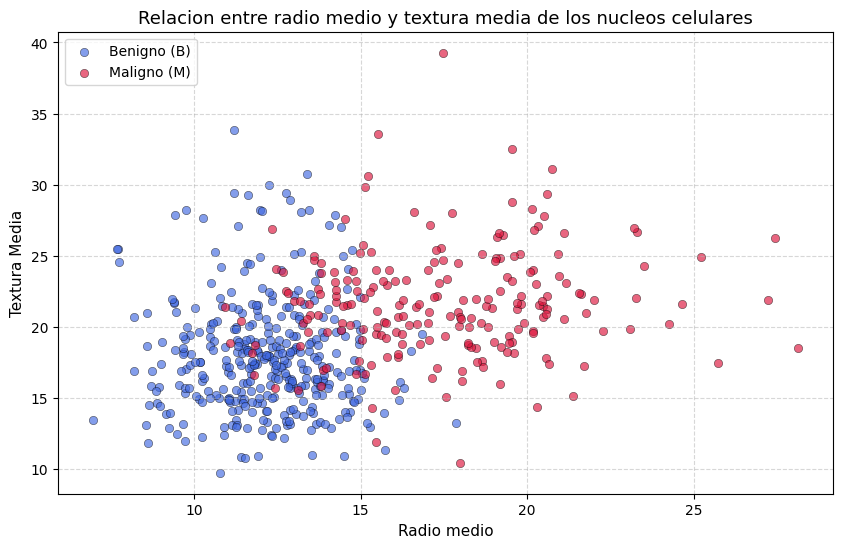

In [3]:
#1 Revisar la estructura, tipos de datos y distribucion de clases
print("---Informacion general del dataframe ---")
df.info()

print("\n--- Distribucion de diagnosticos (B= Benigno, M= Maligno) ---")
print(df['diagnosis'].value_counts())

#2 Resumen estadistico de las 10 variables principales
variables_principales = [
    'mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension'
]
print("\n-- Resumen estadistico de las variables principales --")
display(df[variables_principales].describe().T)

#3 Diagrama de dispersion: mean radius vs mean texture
plt.figure(figsize=(10,6))

benignos = df[df['diagnosis'] == 'B']
malignos = df[df['diagnosis'] == 'M']

plt.scatter(benignos['mean radius'], benignos['mean texture'], color='royalblue', alpha= 0.65, edgecolors = 'k', linewidth= 0.4, label= 'Benigno (B)')
plt.scatter(malignos['mean radius'], malignos['mean texture'], color='crimson', alpha= 0.65, edgecolors = 'k', linewidth= 0.4, label= 'Maligno (M)')

plt.title('Relacion entre radio medio y textura media de los nucleos celulares', fontsize=13)
plt.xlabel('Radio medio', fontsize=11)
plt.ylabel('Textura Media', fontsize=11)
plt.legend(loc='upper left', fontsize= 10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Ejercicio 3: Limpieza y Preprocesamiento de Datos
Descripcion: Se crea una copia del DataFrame original para preservar la integridad de los datos crudos. Primero se auditan posibles valores faltantes, espacios vacíos o caracteres anómalos (?), estableciendo una regla de imputación con la mediana en caso de detectarse registros incompletos. Posteriormente, se utilizan los percentiles 25 (Q_1) y 75 (Q_3) de NumPy para calcular el Rango Intercuartílico (IQR) sobre la variable clave de tamaño tumoral mean area, filtrando el conjunto de datos para conservar únicamente las muestras dentro de los límites estadísticos [Q_1 - 1.5 \times IQR, \, Q_3 + 1.5 \times IQR].

In [4]:
#De preferencia se trabaja sobre una copia para cuidar el data set original
df_limpio = df.copy()

#1 Deteccion de nulos, celdas vacias o codigos especiales (?)
df_limpio.replace(['',' ','?'], np.nan, inplace=True)
nulos_por_columna = df_limpio.isnull().sum()
total_nulos= nulos_por_columna.sum()
print(f"Total de valores nulos o extraños detectados: {total_nulos}")

#En caso de que hayan nulos se meten a la mediana
if total_nulos > 0:
  cols_numericas = df_limpio.select_dtypes(include=[np.number]).column
  df_limpio[cols_numericas] = df_limpio[cols_numericas].fillna(df_limpio[cols_numericas].median())
  print("Valores faltantes juntos con la mediana")
else:
    print("El data set esta limpio, osea no tiene valores nulos")

#Verificar si hay filas duplicadas
duplicados = df_limpio.duplicated().sum()
print(f"Filas duplicadas encontradas: {duplicados}")

#2 Tratamiento de valores atipicos u Outliers en mean area con NumPy
Q1= np.percentile(df_limpio['mean area'], 25)
Q3= np.percentile(df_limpio['mean area'], 75)
IQR= Q3-Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"\n--- IQR en mean area ---")
print(f"Q1(%25): {Q1:.2f} | Q3(%75): {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Limite inferior: {limite_inferior:.2f} | Limite superior: {limite_superior:.2f}")

#Filtrar el DataFrame
filas_antes = df_limpio.shape[0]
outliers_detectados = df_limpio[(df_limpio['mean area'] < limite_inferior) | (df_limpio['mean area'] > limite_superior)]
print(f"\nCantidad de outliers eliminados en mean area: {outliers_detectados.shape[0]}")
print("Distribucion de clases en los outliers eliminados:")
print(outliers_detectados['diagnosis'].value_counts())

df_limpio = df_limpio[(df_limpio['mean area'] >= limite_inferior) & (df_limpio['mean area'] <= limite_superior)]
print(f"\nRegistros antes del filtro IQR: {filas_antes} | Registros conservados: {df_limpio.shape[0]}")

Total de valores nulos o extraños detectados: 0
El data set esta limpio, osea no tiene valores nulos
Filas duplicadas encontradas: 0

--- IQR en mean area ---
Q1(%25): 420.30 | Q3(%75): 782.70 | IQR: 362.40
Limite inferior: -123.30 | Limite superior: 1326.30

Cantidad de outliers eliminados en mean area: 25
Distribucion de clases en los outliers eliminados:
diagnosis
M    25
Name: count, dtype: int64

Registros antes del filtro IQR: 569 | Registros conservados: 544


## Ejercicio 4: Entrenamiento y Evaluación del Árbol de Decisión

Descripcion: Quitamos el identificador (id) y la etiqueta original (diagnosis) para construir la matriz de características X, y se transforma la variable objetivo y a formato numérico binario (1 para Maligno y 0 para Benigno). Los datos se dividen en 75% entrenamiento y 25% prueba con random_state=42 y partición estratificada (stratify=y). Se entrena un clasificador DecisionTreeClassifier (con max_depth=4 para prevenir el sobreajuste y asegurar una alta interpretabilidad clínica), se calculan las métricas de accuracy_score y classification_report, se extraen las variables con mayor importancia predictiva y se grafica la jerarquía del árbol con plot_tree.

Exactitud en Entrenamiento: 0.9853 (98.53%)
Exactitud en Prueba: 0.8971 (89.71%)

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

 Benigno (0)       0.89      0.97      0.92        89
 Maligno (1)       0.92      0.77      0.84        47

    accuracy                           0.90       136
   macro avg       0.90      0.87      0.88       136
weighted avg       0.90      0.90      0.89       136

--- Top 5 caracteristicas mas importantes del modelo ---
worst radius            0.742776
worst concave points    0.104355
mean texture            0.056086
worst smoothness        0.030192
worst texture           0.019844
dtype: float64


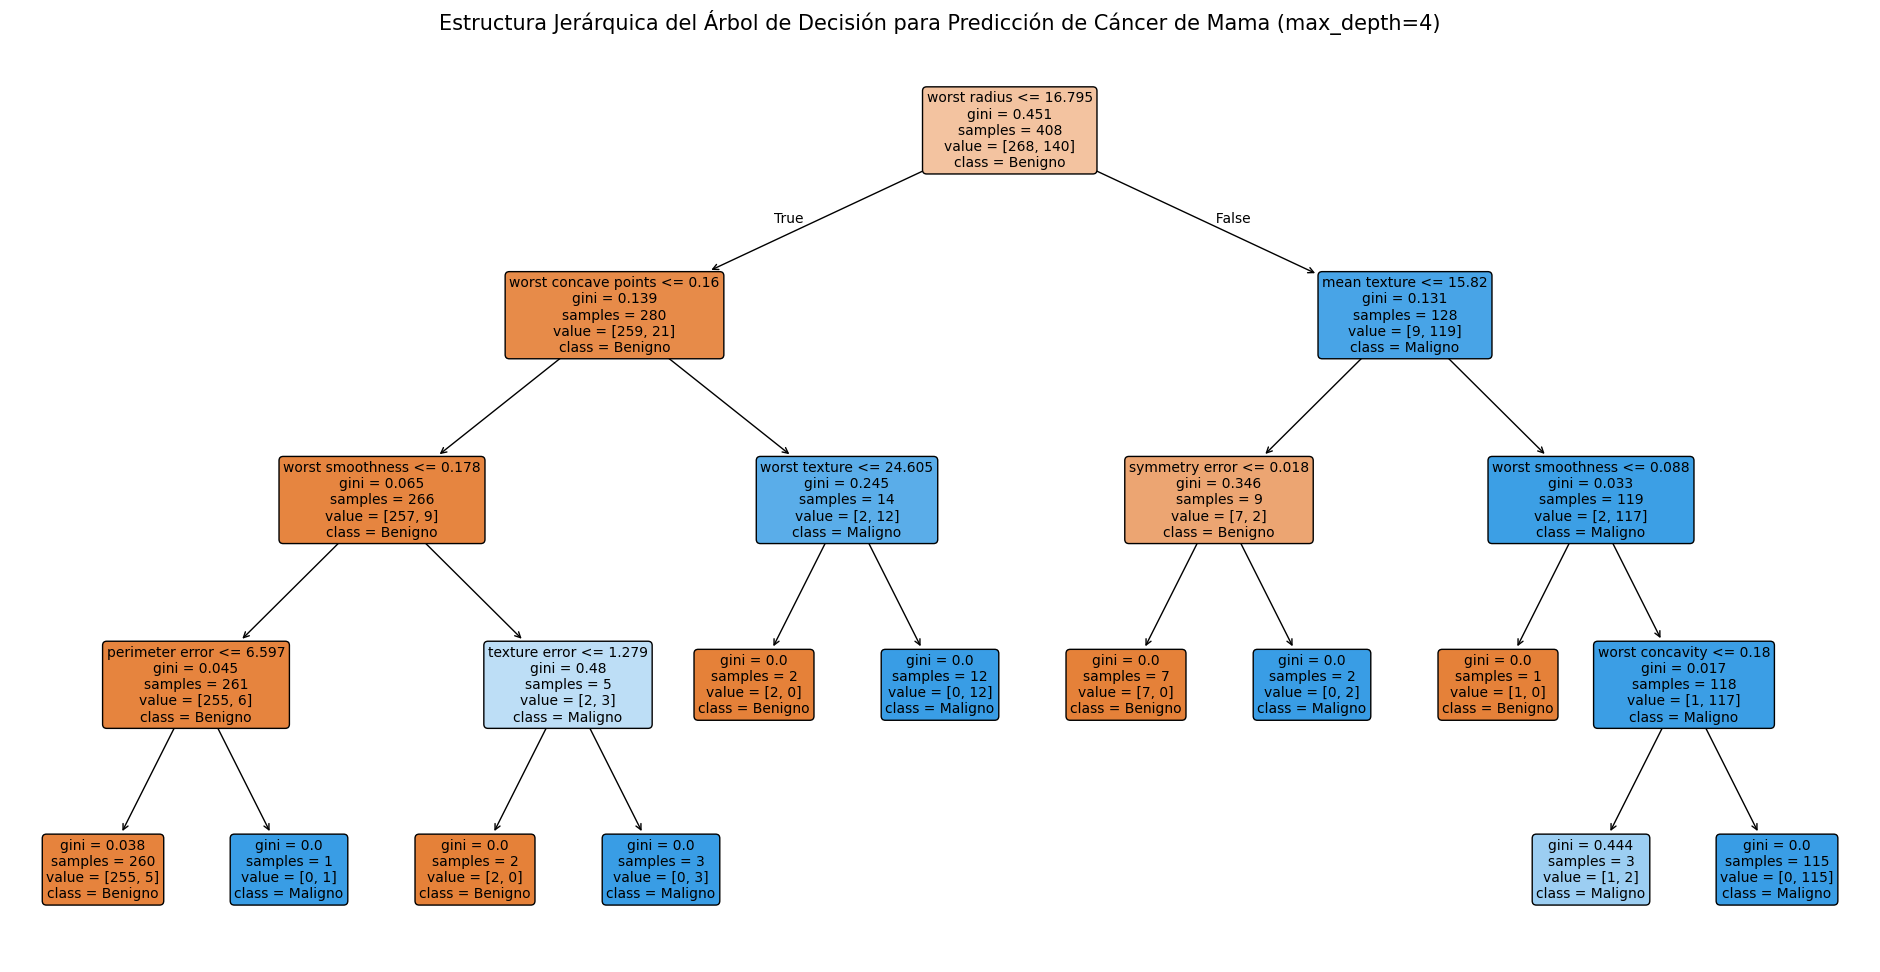

In [5]:
#1 Preparacion de los datos: Excluir 'id' y 'diagnosis' en X; codificar M=1 y B=0 en y
x = df_limpio.drop(['id', 'diagnosis'], axis=1)
y = df_limpio['diagnosis'].map({'M': 1, 'B': 0})

#2 Particiones en entrenamiento (75%) y prueba (%25)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)

#3 Empezar el entrenamiento del arbol de decision
modelo_arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo_arbol.fit(x_train, y_train)

#Prediccion del conjunto de prueba
y_pred = modelo_arbol.predict(x_test)

#Evaluacion de metricas
exactitud_train = accuracy_score(y_train, modelo_arbol.predict(x_train))
exactitud_test = accuracy_score(y_test, y_pred)

print(f"Exactitud en Entrenamiento: {exactitud_train:.4f} ({exactitud_train*100:.2f}%)")
print(f"Exactitud en Prueba: {exactitud_test:.4f} ({exactitud_test*100:.2f}%)")
print("\n--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred, target_names=['Benigno (0)', 'Maligno (1)']))


#Extracción de las 5 características más determinantes
importancias = pd.Series(modelo_arbol.feature_importances_, index=x.columns).sort_values(ascending=False)
print("--- Top 5 caracteristicas mas importantes del modelo ---")
print(importancias.head(5))


#4 Visualización de la estructura jerárquica del Árbol de Decisión
plt.figure(figsize=(24, 12))
plot_tree(
    modelo_arbol,
    feature_names=list(x.columns),
    class_names=['Benigno', 'Maligno'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Estructura Jerárquica del Árbol de Decisión para Predicción de Cáncer de Mama (max_depth=4)", fontsize=15)
plt.show()



